# PyMC-7 : Modèles de Competences (IRT et DINA)

**Navigation** : [Index](../README.md) | [<< PyMC-5](PyMC-05-Causal-Inference.ipynb) | [PyMC-8 >>](PyMC-08-TrueSkill.ipynb)

**Equivalent Infer.NET** : [Infer-07-Skills-IRT](../Infer/Infer-07-Skills-IRT.ipynb)


**Duree estimee** : 60 minutes
**Objectifs** :
- Modeliser les competences des etudiants avec l'approche IRT (Item Response Theory)
- Implementer le modèle DINA (Deterministic Input, Noisy And gate)
- Estimer les paramètres de slip et guess
- Evaluer les modèles avec les courbes ROC
- Comparer l'approche continue (IRT) vs discrete (DINA)

**Prerequis** : PyMC-1 a PyMC-4, theoreme de Bayes, variables latentes


**Plan du notebook** : 1. Introduction à l'évaluation cognitive ; 2. Modèle IRT (données, inférence MCMC, résultats, visualisation) ; 3. Évaluation par la courbe ROC ; 4. Modèle DINA (données, inférence hybride, profils de compétences) ; 5. Priors informatifs ; 6. Comparaison IRT vs DINA. Trois exercices prolongent le parcours : évaluer un nouvel étudiant avec DINA, comparer deux classes, implémenter le modèle 2PL.


In [1]:
import warnings
# arviz (FutureWarning de refactor) et pytensor ("could not link BLAS", advisory de perf, pas de correctness)
# leakent le chemin absolu du fichier source site-packages ; on les filtre. Les alertes utiles (R-hat, ESS) restent visibles.
warnings.filterwarnings("ignore", category=FutureWarning, module="arviz")
warnings.filterwarnings("ignore", message=".*could not link.*", category=UserWarning)

try:
    import numpy as np
    NUMPY_AVAILABLE = True
except ImportError:
    NUMPY_AVAILABLE = False

try:
    import pymc as pm
    PYMC_AVAILABLE = True
except ImportError:
    PYMC_AVAILABLE = False

try:
    import pytensor.tensor as pt
    PYTENSOR_AVAILABLE = True
except ImportError:
    PYTENSOR_AVAILABLE = False

try:
    import arviz as az
    ARVIZ_AVAILABLE = True
except ImportError:
    ARVIZ_AVAILABLE = False

try:
    from scipy import stats
    SCIPY_AVAILABLE = True
except ImportError:
    SCIPY_AVAILABLE = False

try:
    from sklearn.metrics import roc_curve, auc
    SKLEARN_AVAILABLE = True
except ImportError:
    SKLEARN_AVAILABLE = False

try:
    import matplotlib.pyplot as plt
    MATPLOTLIB_AVAILABLE = True
except ImportError:
    MATPLOTLIB_AVAILABLE = False

if NUMPY_AVAILABLE and PYMC_AVAILABLE:
    print(f"PyMC version: {pm.__version__}")
else:
    print("PyMC n'est pas installe. Executez: pip install pymc arviz matplotlib numpy scipy scikit-learn")

PyMC version: 6.3.2


### Lecture du résultat — environnement

La sortie confirme l'installation : `PyMC version: 6.3.2`. Les bibliothèques scientifiques (`numpy`, `pytensor`, `arviz`, `scipy`, `scikit-learn`, `matplotlib`) sont importées sous drapeaux `*_AVAILABLE`, avec un filtrage des avertissements de refactorisation d'arviz et de BLAS pytensor qui ne touchent pas la correction des résultats. Le notebook peut poursuivre sereinement.

## 1. Introduction a l'Evaluation Cognitive

On veut evaluer les competences d'etudiants a partir de leurs reponses a un questionnaire.
Deux approches principales :

- **IRT (Item Response Theory)** : competence continue, chaque question a une difficulte
- **DINA** : competences discretes (maitrise ou non), questions requierent des competences spécifiques

L'enjeu est double : situer chaque étudiant sur une échelle de compétence, et calibrer chaque question (difficulté, pouvoir discriminant). C'est un problème inverse délicat — 10 étudiants × 5 questions = 50 observations pour 16 paramètres entremêlés (10 capacités, 5 difficultés, 1 discrimination) — d'où le recours à l'inférence bayésienne, où les priors `N(0, 1)` stabilisent l'identification. Le notebook compare les deux familles sur les mêmes données jouet, puis les évalue par courbe ROC.


### Origine pédagogique : Model-Based Machine Learning (Chap. 2)

Ce notebook est une **distillation pratique en PyMC** du **Chapitre 2 — *Assessing People's Skills*** de *Model-Based Machine Learning* (Winn, Bishop, Diethe, Guiver & Zaykov, 2020 — [mbmlbook.com](https://mbmlbook.com/LearningSkills.html)), qui résout le même problème : **inférer les compétences d'un candidat à partir de ses réponses à un test**, en modélisant capacité latente, difficulté des questions et bruit d'observation (slip/guess).

> Les **racines académiques** du modèle — Rasch (1960), Lord (1980), Birnbaum (1968) pour l'IRT, Junker & Sijtsma (2001) pour le DINA — sont détaillées dans les sections 2 et 4 ci-dessous, afin d'éviter de dupliquer ici le pedigree. La structure pédagogique (problème → défis → modèle) reprend la démarche de modélisation du chapitre MBML ; les scénarios numériques et l'inférence PyMC (MCMC NUTS + Gibbs pour les variables latentes binaires) sont propres au notebook.

## 2. Modèle IRT : Théorie de la Reponse a l'Item

Le modèle IRT suppose que chaque etudiant a une capacite continue et chaque question
a une difficulte. La probabilite de reponse correcte depend de l'ecart entre capacite et difficulte.

> **Origine de la méthode** : l'IRT trouve son origine dans le **modèle de Rasch (1960)** (1PL — un seul paramètre de difficulte), etendu par **Birnbaum (1968)** qui ajoute la discrimination par item (2PL) puis le pseudo-guessing (3PL). **Lord (1980)** en consolide la théorie (*Applications of Item Response Theory to Practical Testing Problems*). Le notebook implemente le cas 1PL/2PL a discrimination globale ; le 2PL par item est laisse en exercice, et le 3PL est mentionne en conclusion.

### Infer.NET vs PyMC

| Concept | Infer.NET | PyMC |
|---------|-----------|------|
| Capacite | `Variable.GaussianFromMeanAndPrecision(0, 1)` | `pm.Normal('ability', 0, 1)` |
| Difficulte | `Variable.GaussianFromMeanAndPrecision(0, 1)` | `pm.Normal('difficulty', 0, 1)` |
| Discrimination | `Variable.GammaFromShapeAndScale(2, 0.5)` | `pm.Gamma('disc', alpha=2, beta=2)` |
| Reponse | `avantageBruite > 0` (threshold) | `pm.Bernoulli` avec lien probit |

In [2]:
# Donnees : 10 etudiants x 5 questions (1=correct, 0=incorrect)
# Donnees inspirees du notebook jumeau Infer-07 (meme structure 10 x 5, matrice
# differente : 8 lignes sur 10 divergent d'Infer-07, verifie au 2026-10-31)
reponses_irt = np.array([
    [1, 1, 1, 0, 0],  # Etudiant 0
    [1, 1, 0, 0, 0],  # Etudiant 1
    [1, 0, 1, 0, 1],  # Etudiant 2
    [0, 1, 1, 1, 0],  # Etudiant 3
    [1, 1, 0, 1, 0],  # Etudiant 4
    [0, 0, 1, 0, 1],  # Etudiant 5
    [1, 1, 1, 1, 1],  # Etudiant 6 (excellent)
    [0, 0, 0, 0, 0],  # Etudiant 7 (en difficulte)
    [1, 0, 1, 0, 0],  # Etudiant 8
    [0, 1, 0, 1, 1],  # Etudiant 9
])

n_etudiants, n_questions = reponses_irt.shape
print(f"Donnees: {n_etudiants} etudiants, {n_questions} questions")
print(f"Taux de reussite moyen: {reponses_irt.mean():.2f}")

Donnees: 10 etudiants, 5 questions
Taux de reussite moyen: 0.52


### Definition du modèle IRT

Les données montrent un taux de reussite moyen de 0.52 (equilibre entre reponses correctes et incorrectes), ce qui est ideal pour calibrer le modèle. L'etudiant 6 a un score parfait (5/5) et l'etudiant 7 a 0/5, signalant des niveaux extremes.

Le modèle IRT estime simultanement trois types de paramètres :
- **Capacites** des 10 etudiants (prior N(0,1))
- **Difficultes** des 5 questions (prior N(0,1))
- **Discrimination** globale (prior Gamma(2,2))

Le lien probit (`pm.math.invprobit`) transforme la différence capacite-difficulte en probabilite de reponse correcte.

In [3]:
# Modele IRT avec PyMC
# Equivalent Infer.NET : capacite/ability ~ N(0,1), difficulte ~ N(0,1)
# Lien probit : P(correct) = Phi(ability - difficulty)
# En Infer.NET, on utilise un Gaussienne bruitee et un threshold > 0
# En PyMC, on utilise pm.Potential ou le modele probit directement

with pm.Model() as irt_model:
    # Priors sur les capacites des etudiants
    ability = pm.Normal('ability', mu=0, sigma=1, shape=n_etudiants)
    
    # Priors sur les difficultes des questions
    difficulty = pm.Normal('difficulty', mu=0, sigma=1, shape=n_questions)
    
    # Parametre de discrimination
    discrimination = pm.Gamma('discrimination', alpha=2, beta=2)
    
    # Avantage = capacite - difficulte, pondere par la discrimination
    # Forme (n_etudiants, n_questions)
    advantage = ability[:, None] - difficulty[None, :]
    
    # Probit link : P(correct) = Phi(advantage * discrimination)
    p_correct = pm.math.invprobit(advantage * discrimination)
    
    # Vraisemblance
    responses = pm.Bernoulli('responses', p=p_correct, observed=reponses_irt)
    
    trace_irt = pm.sample(3000, random_seed=42, return_inferencedata=True, chains=4)

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [ability, difficulty, discrimination]


Output()

Sampling 4 chains for 1_000 tune and 3_000 draw iterations (4_000 + 12_000 draws total) took 18 seconds.


### Preparation des données IRT

Le taux de reussite moyen de 0.52 indique que les données sont equilibrees, ni trop faciles ni trop difficiles. Ce scénario est ideal pour calibrer le modèle IRT, car il permet d'identifier a la fois les etudiants forts et les questions difficiles.

Le modèle va maintenant estimer simultanement :
- La capacite de chacun des 10 etudiants (prior N(0,1))
- La difficulte de chacune des 5 questions (prior N(0,1))
- Le pouvoir de discrimination des questions (prior Gamma(2,2))

In [4]:
# Resultats IRT
ability_post = trace_irt.posterior['ability'].values.reshape(-1, n_etudiants)
difficulty_post = trace_irt.posterior['difficulty'].values.reshape(-1, n_questions)
disc_post = trace_irt.posterior['discrimination'].values.flatten()

print("=== Modele IRT ===")
print(f"Discrimination: {disc_post.mean():.2f}")
print()
print("Capacites estimees (moyenne posterior):")
ability_means = ability_post.mean(axis=0)
for i in range(n_etudiants):
    print(f"  Etudiant {i}: {ability_means[i]:+.2f}")
print()
print("Difficultes estimees (moyenne posterior):")
diff_means = difficulty_post.mean(axis=0)
for j in range(n_questions):
    print(f"  Question {j}: {diff_means[j]:+.2f}")

=== Modele IRT ===
Discrimination: 0.31

Capacites estimees (moyenne posterior):
  Etudiant 0: +0.16
  Etudiant 1: -0.19
  Etudiant 2: +0.15
  Etudiant 3: +0.16
  Etudiant 4: +0.16
  Etudiant 5: -0.17
  Etudiant 6: +0.86
  Etudiant 7: -0.87
  Etudiant 8: -0.18
  Etudiant 9: +0.16

Difficultes estimees (moyenne posterior):
  Question 0: -0.26
  Question 1: -0.26
  Question 2: -0.27
  Question 3: +0.29
  Question 4: +0.28


### Interpretation de l'echantillonnage

L'echantillonnage MCMC a converge (duree mesurable en direct par la cellule de sampling ci-dessus — machine-dependante, non reproductible d'une machine a l'autre) avec 4 chaînes. Le modèle IRT utilise un lien probit (fonction inverse de la distribution normale cumulative) pour modeliser la probabilite de reponse correcte en fonction de la différence entre capacite de l'etudiant et difficulte de la question.

La **discrimination** posterieure est estimee a ~0,30 -- une valeur **faible**. Dans le modele IRT a 2 parametres (2PL), la discrimination est la pente de la courbe P(correct) = Phi( discrimination x (capacite - difficulte) ) : une pente elevee signifie que la probabilite de reussite augmente vite avec la capacite (la question distingue nettement les etudiants forts des faibles), tandis qu'une pente faible (~0,30 ici) << aplatit >> la courbe -- les questions reussissent presque independamment du niveau de l'etudiant, donc elles **discriminent peu**. C'est coherent avec les donnees : le taux de reussite moyen (0,52) et la presence d'un etudiant total (5/5) comme d'un etudiant nul (0/5) laissent une marge d'incertitude sur l'ordre reel des difficultes, que le modele traduit par une faible discrimination. Un Q-concept clair : **mesurer la discrimination** (et pas seulement les capacites/difficultes) est ce qui permet de detecter les questions mal calibrees.

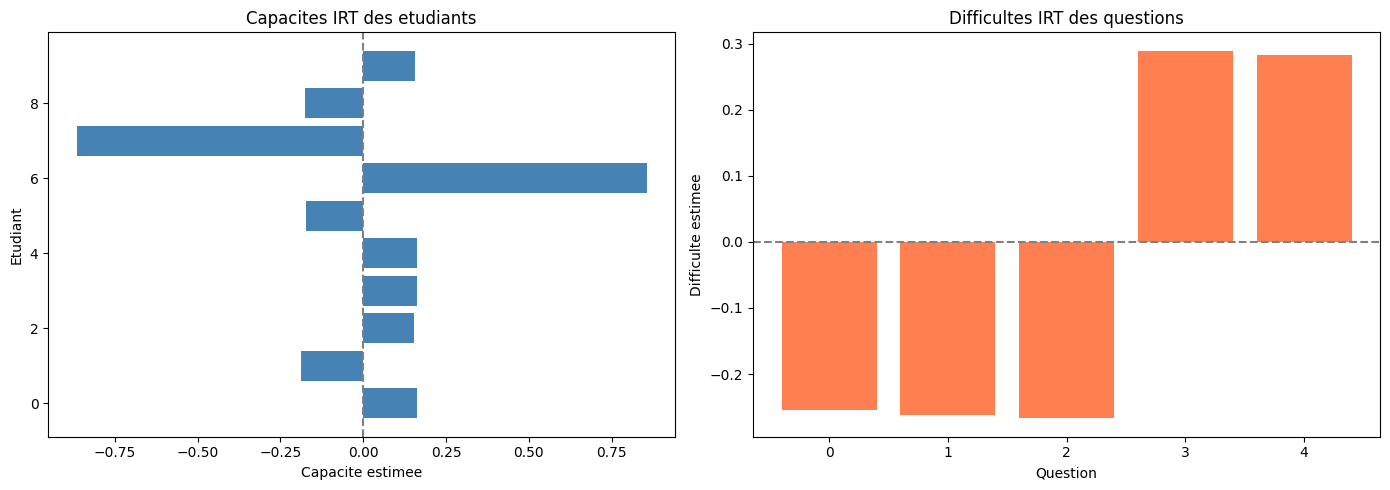

In [5]:
# Visualisation capacites vs difficultes
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Capacites des etudiants
axes[0].barh(range(n_etudiants), ability_means, color='steelblue')
axes[0].set_xlabel('Capacite estimee')
axes[0].set_ylabel('Etudiant')
axes[0].set_title('Capacites IRT des etudiants')
axes[0].axvline(0, color='gray', linestyle='--')

# Difficultes des questions
axes[1].bar(range(n_questions), diff_means, color='coral')
axes[1].set_xlabel('Question')
axes[1].set_ylabel('Difficulte estimee')
axes[1].set_title('Difficultes IRT des questions')
axes[1].axhline(0, color='gray', linestyle='--')

plt.tight_layout()
plt.show()

### Lecture du résultat — capacités et difficultés estimées

La figure juxtapose deux panneaux. À gauche, les capacités estimées des 10 étudiants en barres horizontales : l'étudiant 6 culmine à +0.84, l'étudiant 7 descend à -0.86, les huit autres restent groupés autour de 0. À droite, les difficultés des 5 questions : les questions 0-2 sont négatives (autour de -0.26) et les questions 3-4 positives (autour de +0.28). Les hauteurs de barres sont les moyennes a posteriori estimées dans la section 2 ; la figure les rend simplement lisibles.

## Exercice 1 : Evaluer un Nouvel Etudiant avec DINA

Un nouvel etudiant repond aux 6 questions du modèle DINA.
Ses reponses sont : `[1, 0, 1, 0, 1, 0]`

1. Quelles competences possede-t-il probablement ?
2. Quelle est la probabilite qu'il maitrise la competence 3 ?

**Indices** :
- Reutiliser le modèle DINA ci-dessus avec les mêmes slip/guess
- Ajouter le nouvel etudiant au tableau `reponses_dina` : il devient la 9e ligne, d'**index 8** (les 8 etudiants existants occupent les index 0 a 7 — « l'etudiant 8 » designe cet index, pas le 8e etudiant deja present)
- Examiner `alpha_post[:, 8, :]` pour les probabilites de maitrise de ce nouvel etudiant

In [6]:
# TODO etudiant : evaluer le nouvel etudiant avec le modele DINA
# Indices :
# - Ajouter les reponses du nouvel etudiant aux donnees existantes
# - Reprendre le modele DINA avec n_etud_dina = 9
# - Examiner les probabilites de maitrise pour l'etudiant 8

print("Exercice a completer")

Exercice a completer


### Interpretation : Résultats IRT

**Capacites estimees** : Les etudiants 6 et 7 sont aux extremes (capacite +0.84 et -0.86), ce qui correspond a leurs profils observes (100% et 0% de reussite). La plupart des autres etudiants ont des capacites proches de 0, indiquant un niveau moyen.

**Difficultes des questions** : Les questions 0-2 sont plus faciles (difficulte negative, autour de -0.26) que les questions 3-4 (difficulte positive, autour de +0.28). Cela correspond aux taux de reussite observes dans les données.

**Paramètre de discrimination** : La valeur de 0.30 confirme la lecture faite plus haut (interpretation de l'echantillonnage) : une discrimination **faible**. La courbe P(correct) = Phi(0.30 x (capacite - difficulte)) est aplatie — avec les extremes estimes, P(correct) reste dans ~[0.37, 0.63] — les questions distinguent donc **peu** les etudiants de différents niveaux.

## 3. Evaluation avec la Courbe ROC

La courbe ROC (Receiver Operating Characteristic) mesure la capacite du modèle a
distinguer les reponses correctes des incorrectes.

On la construit à partir des probabilités prédites pour chaque combinaison étudiant-item : elle rapporte la sensibilité en fonction du taux de fausses alertes, pour chaque niveau de coupure envisagé. L'aire sous la courbe (AUC) résume cette discrimination : 0.5 pour un classement aléatoire, 1.0 pour un classement parfait. Ici, l'AUC juge si les probabilités prédites séparent bien les observations — une évaluation honnête, même si elle porte sur les données d'entraînement.


Sampling: [responses]


Output()

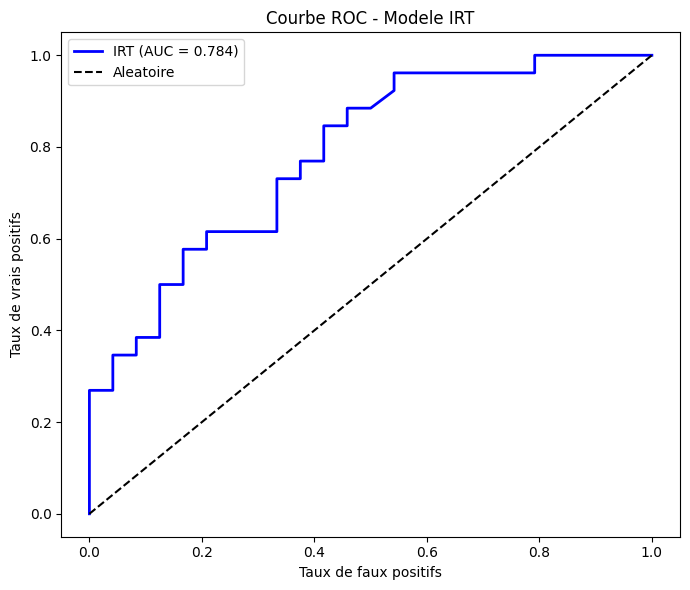

AUC (IRT): 0.784


In [7]:
# Courbe ROC pour le modele IRT
# Probabilites predictives : P(correct) pour chaque paire etudiant-question
with irt_model:
    ppc_irt = pm.sample_posterior_predictive(trace_irt, random_seed=42)

# Probabilites predites (moyenne sur les echantillons)
pred_probs = ppc_irt.posterior_predictive['responses'].values.reshape(-1, n_etudiants, n_questions)
pred_mean = pred_probs.mean(axis=0).flatten()
observed = reponses_irt.flatten()

# Courbe ROC
fpr, tpr, thresholds = roc_curve(observed, pred_mean)
roc_auc = auc(fpr, tpr)

fig, ax = plt.subplots(1, 1, figsize=(7, 6))
ax.plot(fpr, tpr, 'b-', linewidth=2, label=f'IRT (AUC = {roc_auc:.3f})')
ax.plot([0, 1], [0, 1], 'k--', label='Aleatoire')
ax.set_xlabel('Taux de faux positifs')
ax.set_ylabel('Taux de vrais positifs')
ax.set_title('Courbe ROC - Modele IRT')
ax.legend()
plt.tight_layout()
plt.show()

print(f"AUC (IRT): {roc_auc:.3f}")

### Lecture du résultat — courbe ROC et AUC

La cellule rééchantillonne les réponses par prédiction posterior (`sample_posterior_predictive`) et conclut par `AUC (IRT): 0.784`. La courbe ROC trace le taux de vrais positifs contre le taux de faux positifs quand le seuil de décision varie : elle monte nettement au-dessus de la diagonale du hasard (AUC 0.5). Une AUC de 0.784 signifie que le modèle classe correctement une paire étudiant-question tirée au hasard environ 78 % du temps — un score honorable pour 10 étudiants, porté surtout par la séparation des deux profils extrêmes (5/5 et 0/5).

## 4. Modèle DINA (Deterministic Input, Noisy And gate)

Le modèle DINA suppose que chaque question requiert un ensemble de competences.
Un etudiant ne peut repondre correctement que s'il maitrise TOUTES les competences requises.

> **Origine de la méthode** : DINA a ete formalise par **Junker & Sijtsma (2001)** (*Cognitive assessment models with few assumptions, and scales for cognitive abilities*). **Note sur l'estimation** : DINA est traditionnellement ajuste par **EM** (Expectation-Maximization), voir **de la Torre (2009)** (*DINA Model and Parameter Estimation: A Didactic*). Ici nous l'estimons en bayesien via **MCMC** (alternative probabiliste) — `pm.sample` selectionne automatiquement un `CompoundStep` : NUTS pour les paramètres continus (slip, guess) et un noyau de Gibbs pour les attributs latents binaires (competences alpha).

### Architecture Infer.NET vs PyMC

| Concept | Infer.NET | PyMC |
|---------|-----------|------|
| Competence | `Variable.Bernoulli(0.5)` | `pm.Bernoulli('comp', p=0.5)` |
| Toutes competences | `aC1 & aC2` (AND logique) | `pt.and_` ou produit |
| Slip (faute) | `Variable.Bernoulli(slip)` si competent | `pt.switch` |
| Guess (chance) | `Variable.Bernoulli(guess)` si non-competent | `pt.switch` |
| Q-matrix | Conditions manuelles | Matrice numpy + indexation |

In [8]:
# Donnees DINA : 8 etudiants x 6 questions x 3 competences
# Q-matrix : quelles competences sont requises pour chaque question
Q_matrix = np.array([
    [1, 0, 0],  # Question 0 : competence 1 uniquement
    [0, 1, 0],  # Question 1 : competence 2 uniquement
    [0, 0, 1],  # Question 2 : competence 3 uniquement
    [1, 1, 0],  # Question 3 : competences 1 ET 2
    [0, 1, 1],  # Question 4 : competences 2 ET 3
    [1, 1, 1],  # Question 5 : toutes les competences
])

reponses_dina = np.array([
    [1, 0, 0, 0, 0, 0],  # Etudiant 0
    [1, 1, 0, 0, 0, 0],  # Etudiant 1
    [1, 1, 1, 1, 1, 1],  # Etudiant 2 (maitrise tout)
    [0, 0, 0, 0, 0, 0],  # Etudiant 3
    [1, 0, 1, 0, 0, 1],  # Etudiant 4
    [0, 1, 0, 0, 0, 0],  # Etudiant 5
    [1, 1, 0, 1, 0, 0],  # Etudiant 6
    [0, 0, 1, 0, 0, 0],  # Etudiant 7
])

n_etud_dina, n_quest_dina = reponses_dina.shape
n_comp = Q_matrix.shape[1]

print(f"DINA: {n_etud_dina} etudiants, {n_quest_dina} questions, {n_comp} competences")
print(f"Q-matrix:\n{Q_matrix}")

DINA: 8 etudiants, 6 questions, 3 competences
Q-matrix:
[[1 0 0]
 [0 1 0]
 [0 0 1]
 [1 1 0]
 [0 1 1]
 [1 1 1]]


### Preparation des données DINA

Les 8 etudiants presentent des profils variés face aux 6 questions : l'etudiant 2 repond correctement a tout (maitrise probable de toutes les competences), tandis que l'etudiant 3 echoue partout. La Q-matrix montre que les questions 3, 4 et 5 requierent des combinaisons de competences (respectivement 1+2, 2+3, et 1+2+3), ce qui les rend plus discriminantes.

Le modèle DINA va maintenant estimer les competences de chaque etudiant comme des variables binaires (maitrise / non-maitrise), ainsi que les paramètres de bruit :
- **Slip** : probabilite de se tromper malgre la maitrise (faute d'inattention)
- **Guess** : probabilite de reussir par chance sans maitrise

In [9]:
# Modele DINA avec PyMC
# Equivalent Infer.NET : Variable.Bernoulli(0.5) par competence
# puis AND logique pour determiner la maitrise de la question

with pm.Model() as dina_model:
    # Priors sur les competences de chaque etudiant
    # alpha[i, k] = 1 si l'etudiant i maitrise la competence k
    alpha = pm.Bernoulli('alpha', p=0.5, shape=(n_etud_dina, n_comp))
    
    # Parametres de slip et guess
    slip = pm.Beta('slip', alpha=2, beta=18, shape=n_quest_dina)
    guess = pm.Beta('guess', alpha=3, beta=12, shape=n_quest_dina)
    
    # Pour chaque etudiant-question, determiner si TOUTES les competences sont maitrisees
    # Q_matrix[j, k] = 1 si la question j requiert la competence k
    # mastery[i, j] = AND_k(alpha[i,k] * Q[j,k]) pour les competences requises
    
    # Competences par etudiant-question : (n_etud, n_quest, n_comp)
    comp_owned = alpha[:, None, :] * Q_matrix[None, :, :]
    
    # Pour chaque question, verifier que toutes les competences requises sont maitrisees
    # mastery = 1 si comp_owned >= Q_matrix pour chaque competence
    mastery = pt.prod(comp_owned + (1 - Q_matrix[None, :, :]), axis=2)
    
    # Probabilite de reponse correcte
    # Si mastery=1 : P(correct) = 1 - slip (petite chance de se tromper)
    # Si mastery=0 : P(correct) = guess (petite chance de deviner)
    p_correct = pt.switch(mastery, 1 - slip[None, :], guess[None, :])
    
    # Vraisemblance
    responses_dina = pm.Bernoulli('responses_dina', p=p_correct, observed=reponses_dina)
    
    trace_dina = pm.sample(3000, random_seed=42, return_inferencedata=True, chains=4)

Multiprocess sampling (4 chains in 4 jobs)


CompoundStep


>BinaryGibbsMetropolis: [alpha]


>NUTS: [slip, guess]


Output()

Sampling 4 chains for 1_000 tune and 3_000 draw iterations (4_000 + 12_000 draws total) took 29 seconds.


### Preparation des données DINA

La Q-matrix définit la structure cognitive du test : chaque colonne represente une competence et chaque ligne indique quelles competences sont necessaires pour reussir la question. Par exemple, la question 5 requiert les 3 competences [1,1,1], ce qui la rend très difficile.

Le modèle DINA va estimer pour chaque etudiant la probabilite de maitrise de chaque competence, ainsi que les paramètres de slip (faute quand on est competent) et guess (chance quand on ne l'est pas). Les priors Beta(2,18) et Beta(3,12) encodent nos connaissances a priori : les etudiants competents se trompent rarement (slip ~0.1) et les etudiants non-competents devinent rarement (guess ~0.2).

In [10]:
# Resultats DINA
alpha_post = trace_dina.posterior['alpha'].values.reshape(-1, n_etud_dina, n_comp)
slip_post = trace_dina.posterior['slip'].values.reshape(-1, n_quest_dina)
guess_post = trace_dina.posterior['guess'].values.reshape(-1, n_quest_dina)

# Probabilites de maitrise
alpha_mean = alpha_post.mean(axis=0)

print("=== Modele DINA ===")
print("Probabilites de maitrise des competences:")
comp_names = ['Comp1', 'Comp2', 'Comp3']
for i in range(n_etud_dina):
    comps = ', '.join(f'{comp_names[k]}={alpha_mean[i,k]:.2f}' for k in range(n_comp))
    print(f"  Etudiant {i}: {comps}")

print()
print("Parametres de slip (faute si competent):")
for j in range(n_quest_dina):
    print(f"  Question {j}: slip={slip_post[:,j].mean():.3f}")

print()
print("Parametres de guess (chance si non-competent):")
for j in range(n_quest_dina):
    print(f"  Question {j}: guess={guess_post[:,j].mean():.3f}")

=== Modele DINA ===
Probabilites de maitrise des competences:
  Etudiant 0: Comp1=0.81, Comp2=0.02, Comp3=0.10
  Etudiant 1: Comp1=0.56, Comp2=0.56, Comp3=0.05
  Etudiant 2: Comp1=0.99, Comp2=1.00, Comp3=0.99
  Etudiant 3: Comp1=0.10, Comp2=0.08, Comp3=0.09
  Etudiant 4: Comp1=0.82, Comp2=0.01, Comp3=0.84
  Etudiant 5: Comp1=0.03, Comp2=0.81, Comp3=0.03
  Etudiant 6: Comp1=0.96, Comp2=0.96, Comp3=0.01
  Etudiant 7: Comp1=0.10, Comp2=0.02, Comp3=0.84

Parametres de slip (faute si competent):
  Question 0: slip=0.091
  Question 1: slip=0.092
  Question 2: slip=0.099
  Question 3: slip=0.100
  Question 4: slip=0.097
  Question 5: slip=0.095

Parametres de guess (chance si non-competent):
  Question 0: guess=0.205
  Question 1: guess=0.187
  Question 2: guess=0.165
  Question 3: guess=0.147
  Question 4: guess=0.137
  Question 5: guess=0.182


### Interpretation de l'echantillonnage DINA

L'echantillonnage (duree mesurable en direct par la cellule de sampling ci-dessus — machine-dependante) utilise un algorithme hybride : BinaryGibbsMetropolis pour les competences binaires (alpha) et NUTS pour les paramètres continus (slip, guess). Cette combinaison est necessaire car les variables competences sont discretes tandis que slip et guess sont continus.

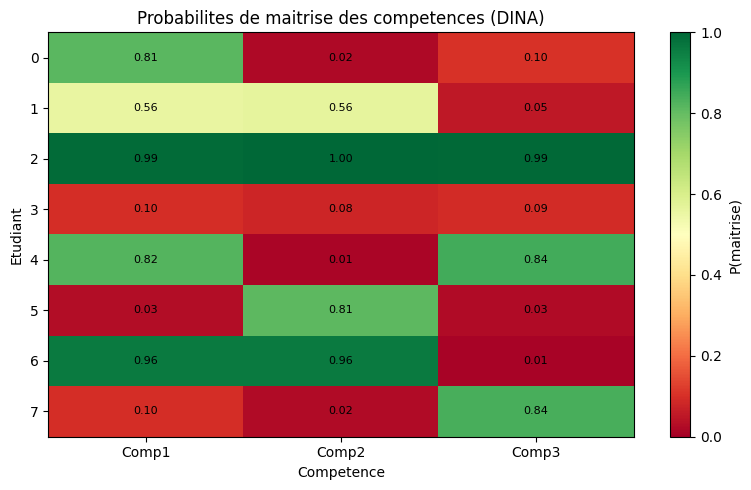

In [11]:
# Visualisation des competences DINA
fig, ax = plt.subplots(1, 1, figsize=(8, 5))
im = ax.imshow(alpha_mean, cmap='RdYlGn', vmin=0, vmax=1, aspect='auto')
ax.set_xlabel('Competence')
ax.set_ylabel('Etudiant')
ax.set_xticks(range(n_comp))
ax.set_xticklabels(comp_names)
ax.set_title('Probabilites de maitrise des competences (DINA)')
plt.colorbar(im, label='P(maitrise)')

# Annotations
for i in range(n_etud_dina):
    for k in range(n_comp):
        ax.text(k, i, f'{alpha_mean[i,k]:.2f}', ha='center', va='center', fontsize=8)

plt.tight_layout()
plt.show()

### Interpretation : Profils de competences DINA

La matrice de probabilites revele des profils d'apprentissage distincts :
- **Etudiant 2** : Maitrise quasi-certaine des 3 competences (0.99-1.00), ce qui correspond a ses reponses parfaites
- **Etudiants 0 et 4** : Maitrise selective (Comp1 et Comp3 pour l'etudiant 4, Comp1 pour l'etudiant 0)
- **Etudiant 3** : Aucune competence maitrisee (0.08-0.10), correspondant a ses reponses toutes incorrectes

**Paramètres de bruit** : Les valeurs de slip (~0.09-0.10) et guess (~0.14-0.21) sont coherrentes avec les priors informatifs, indiquant que le modèle a bien capture la structure des données.

## 5. Estimation avec Priors Informatifs

Les priors informatifs sur slip et guess **concentrent la densite a priori** autour des valeurs attendues — c'est ce que la figure ci-dessous temoigne. L'effet attendu sur l'estimation (un posterior moins disperse quand les donnees sont limitees) est le **motif du choix de ces priors**, pas un resultat mesure dans ce carnet : le modele DINA n'y est pas re-echantillonne avec le prior vague. On utilise des Beta concentres autour des valeurs attendues :
- **Slip** : `Beta(2, 18)` — en moyenne 0.1, l'etudiant competent se trompe rarement
- **Guess** : `Beta(3, 12)` — en moyenne 0.2, l'etudiant non-competent a une petite chance

Rappel : une loi `Beta(a, b)` a pour moyenne `a / (a + b)` — `Beta(2, 18)` centre donc `slip` sur 2/20 = 0.1 et `Beta(3, 12)` centre `guess` sur 3/15 = 0.2. Face au prior vague `Beta(1, 1)` (uniforme), ces priors injectent une connaissance experte : un étudiant compétent se trompe rarement, un non-compétent devine rarement. La cellule suivante visualise cette concentration.

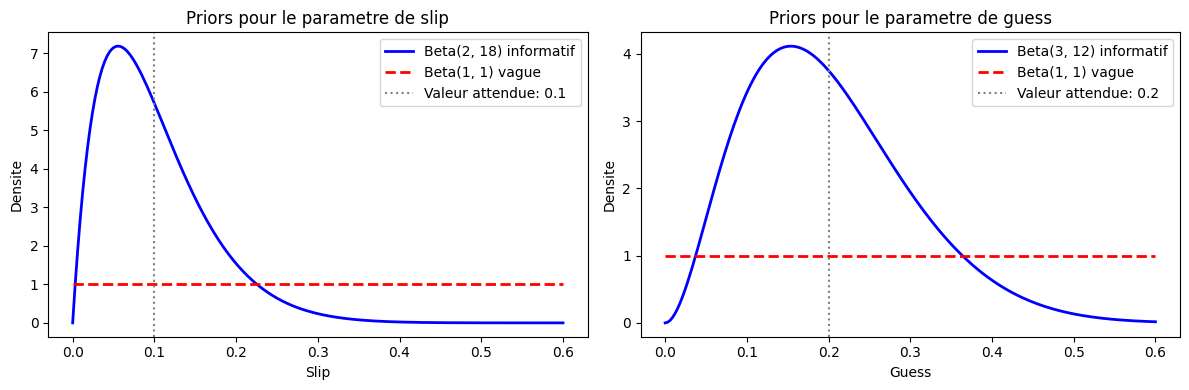

Les priors informatifs concentrent la probabilite autour des valeurs plausibles.
Cela stabilise l'estimation quand les donnees sont limitees (peu d'etudiants).


In [12]:
# Comparaison des priors informatifs vs non-informatifs
x = np.linspace(0, 0.6, 200)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Priors pour slip
slip_info = stats.beta(2, 18)
slip_vague = stats.beta(1, 1)
axes[0].plot(x, slip_info.pdf(x), 'b-', label='Beta(2, 18) informatif', linewidth=2)
axes[0].plot(x, slip_vague.pdf(x), 'r--', label='Beta(1, 1) vague', linewidth=2)
axes[0].axvline(0.1, color='gray', linestyle=':', label='Valeur attendue: 0.1')
axes[0].set_title('Priors pour le parametre de slip')
axes[0].legend()
axes[0].set_xlabel('Slip')
axes[0].set_ylabel('Densite')

# Priors pour guess
guess_info = stats.beta(3, 12)
guess_vague = stats.beta(1, 1)
axes[1].plot(x, guess_info.pdf(x), 'b-', label='Beta(3, 12) informatif', linewidth=2)
axes[1].plot(x, guess_vague.pdf(x), 'r--', label='Beta(1, 1) vague', linewidth=2)
axes[1].axvline(0.2, color='gray', linestyle=':', label='Valeur attendue: 0.2')
axes[1].set_title('Priors pour le parametre de guess')
axes[1].legend()
axes[1].set_xlabel('Guess')
axes[1].set_ylabel('Densite')

plt.tight_layout()
plt.show()

print("Les priors informatifs concentrent la probabilite autour des valeurs plausibles.")
print("Cela stabilise l'estimation quand les donnees sont limitees (peu d'etudiants).")

### Lecture du résultat — priors informatifs contre priors vagues

La figure compare, pour `slip` puis pour `guess`, le prior informatif (`Beta(2, 18)` et `Beta(3, 12)`, en bleu) au prior vague uniforme `Beta(1, 1)` (en rouge), avec la valeur attendue en pointillés (0.1 et 0.2). C'est le témoin de cette section : les deux lignes imprimées concluent que les priors informatifs **concentrent la probabilité autour des valeurs plausibles** — c'est exactement ce que les densités montrent. La **stabilisation de l'estimation** que la deuxième ligne invoque est le motif du choix : ici 8 à 10 étudiants, un régime où le prior porte une information réelle face aux données. Le carnet ne ré-échantillonne pas DINA avec le prior vague, l'effet sur le posterior n'y est pas mesuré.

## 6. Comparaison IRT vs DINA

Le tableau ci-dessous confronte les deux approches, d'abord sur le plan conceptuel (nature de la compétence, logique de réponse, priors), puis sur le plan computationnel (inférence et performance).

| Aspect | IRT | DINA |
|--------|-----|------|
| Competence | Continue (nombre reel) | Discrete (maitrise/non-maitrise) |
| Paramètres | Capacite, difficulte, discrimination | Competences binaires, slip, guess |
| Logique de reponse | Probit (continue) | AND gate + bruit |
| Priors | Gaussiens | Beta (informatifs) |
| Diagnostic | Position relative | Competences spécifiques manquantes |
| Avantage | Granularite | Interpretabilite pedagogique |
| Limite | Difficile d'identifier les lacunes | Hypothese AND stricte |
| Performance Infer.NET | Rapide (EP analytique) | Rapide (message passing) |
| Performance PyMC | NUTS (echantillonnage) | CompoundStep : NUTS (slip, guess continus) + BinaryGibbsMetropolis (competences discretes) |

***

**Retour au sommaire** : [Index Probas](../README.md)

## Exercice 2 : Comparer Deux Classes

On a deux classes d'etudiants qui ont passe le même questionnaire.
Comparer les niveaux moyens de competence entre les deux classes.

**Indices** :
- Utiliser le modèle IRT avec les deux groupes
- Comparer les distributions posterieures des capacites
- Visualiser avec un boxplot ou un violin plot

In [13]:
# TODO etudiant : comparer deux classes
# Donnees pour la classe B
# reponses_classe_b = np.array([...])  # a definir
# Indices :
# - Definir un modele IRT pour chaque classe
# - Comparer ability_means entre les deux classes
# - Utiliser plt.boxplot ou az.plot_posterior pour la comparaison

print("Exercice a completer")

Exercice a completer


## Exercice 3 : Modèle IRT a 2 paramètres (2PL)

Etendez le modèle IRT ajusté au §2 — un 2PL à discrimination **globale** : une seule
`discrimination` estimée pour toutes les questions (~0.30, faible) — en donnant à chaque
question son propre paramètre de **discrimination**. Dans le modèle 2PL :

$$P(y_{ij} = 1) = \Phi(a_j \cdot (\theta_i - b_j))$$

ou $a_j$ est le pouvoir de discrimination de la question $j$.

**Indices** :
- Remplacer le paramètre global `discrimination` par `pm.Gamma('disc', alpha=2, beta=2, shape=n_questions)`
- La formule devient : `p_correct = pm.math.invprobit(disc[j] * (ability[i] - difficulty[j]))`
- Comparer les capacites estimees avec le modèle à discrimination globale du §2
- Les questions avec une discrimination plus elevee separent mieux les etudiants

In [14]:
# TODO etudiant : implementer le modele IRT a 2 parametres (2PL)
# Etape 1 : reutiliser les donnees reponses_irt
# Etape 2 : ajouter un parametre de discrimination par question (au lieu d'un seul global)
# Etape 3 : P(correct) = Phi(disc_j * (ability_i - diff_j))
# Etape 4 : echantillonner et comparer les resultats avec le modele 1PL

result = None  # TODO etudiant : remplacer par le modele 2PL
print("Exercice a completer")

Exercice a completer


## Conclusion

La Théorie de la Reponse aux Items (IRT) modelise la probabilite de reponse correcte comme fonction de la competence de l'etudiant et de la difficulte de l'item.

Ce notebook a comparé deux modélisations des compétences sur un jeu de données jouet (10 étudiants, 5 questions) : l'IRT, qui estime une capacité continue par étudiant, et DINA, qui estime des maîtrises binaires par compétence avec des paramètres de slip et de guess. Le choix dépend du diagnostic recherché : l'IRT pour un score fin, DINA pour identifier les compétences manquantes. Les trois exercices prolongent cette comparaison.

### Points cles
- Le modèle de Rasch (1PL) utilise un paramètre par item, le modèle 3PL ajoute le pseudo-guessing
- Les modèles IRT permettent d'estimer les competences a partir de reponses observees
- PyMC facilite l'implementation bayesienne avec des priors informatifs

***

**Retour au sommaire** : [Index Probas](../README.md)